In [10]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

url = "C:\IT_vedant\Machine Learning\customers.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()
df.info()
df.describe().T

(440, 8)
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicatessen      440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


<>:4: SyntaxWarning: "\I" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\I"? A raw string is also an option.
<>:4: SyntaxWarning: "\I" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\I"? A raw string is also an option.
C:\Users\ASUS\AppData\Local\Temp\ipykernel_31948\3662925102.py:4: SyntaxWarning: "\I" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\I"? A raw string is also an option.
  url = "C:\IT_vedant\Machine Learning\customers.csv"


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.322727,0.468052,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicatessen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0


In [11]:
df.isnull().sum()          # missing values
df.duplicated().sum()      # duplicates
df.nunique()

Channel               2
Region                3
Fresh               433
Milk                421
Grocery             430
Frozen              426
Detergents_Paper    417
Delicatessen        403
dtype: int64

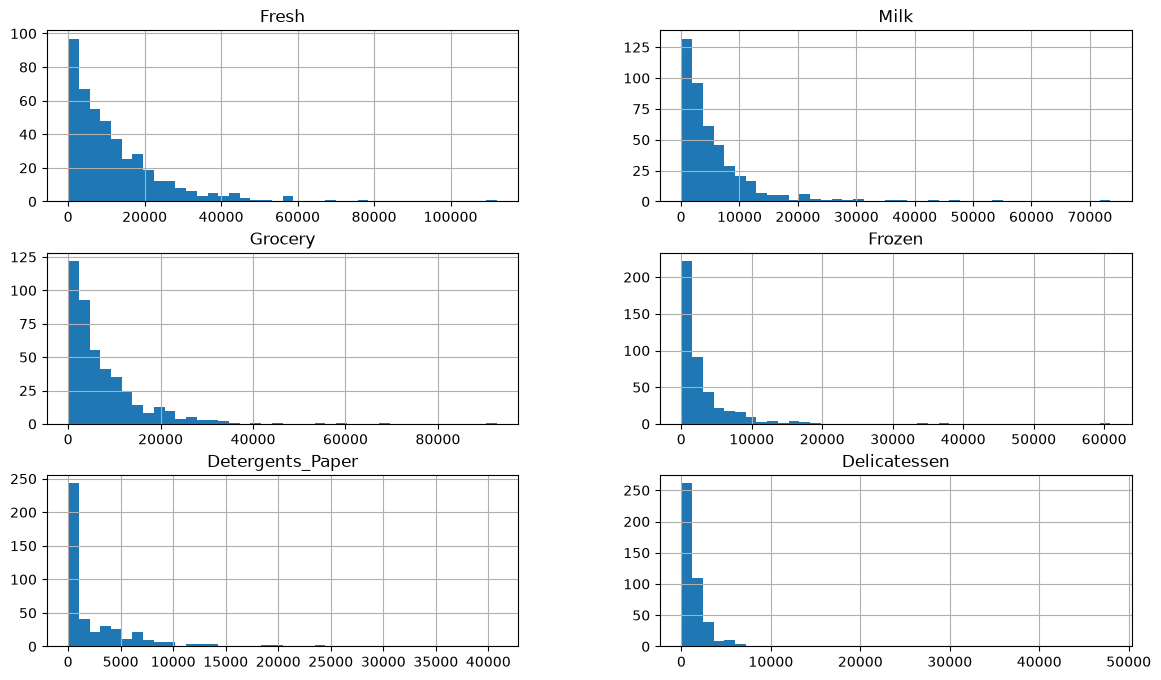

In [12]:
df['Channel'].value_counts()
df['Region'].value_counts()

num_cols = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicatessen']
df[num_cols].hist(bins=40, figsize=(14,8)); plt.show()

In [13]:
df[num_cols].skew().sort_values(ascending=False)

Delicatessen        11.151586
Frozen               5.907986
Milk                 4.053755
Detergents_Paper     3.631851
Grocery              3.587429
Fresh                2.561323
dtype: float64

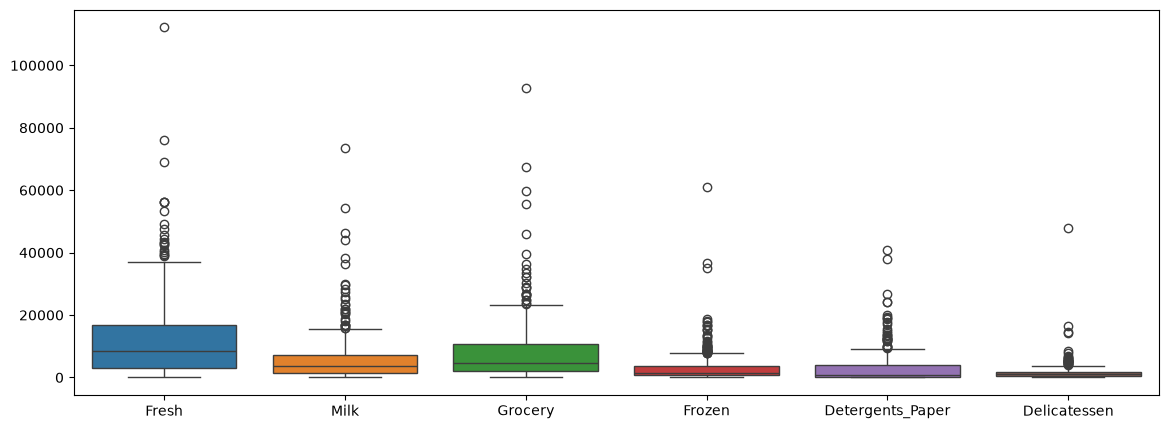

Fresh               20
Milk                28
Grocery             24
Frozen              43
Detergents_Paper    30
Delicatessen        27
dtype: int64


In [14]:
plt.figure(figsize=(14,5))
sns.boxplot(data=df[num_cols]); plt.show()

Q1, Q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
IQR = Q3 - Q1
outliers = ((df[num_cols] < Q1 - 1.5*IQR) | (df[num_cols] > Q3 + 1.5*IQR)).sum()
print(outliers)

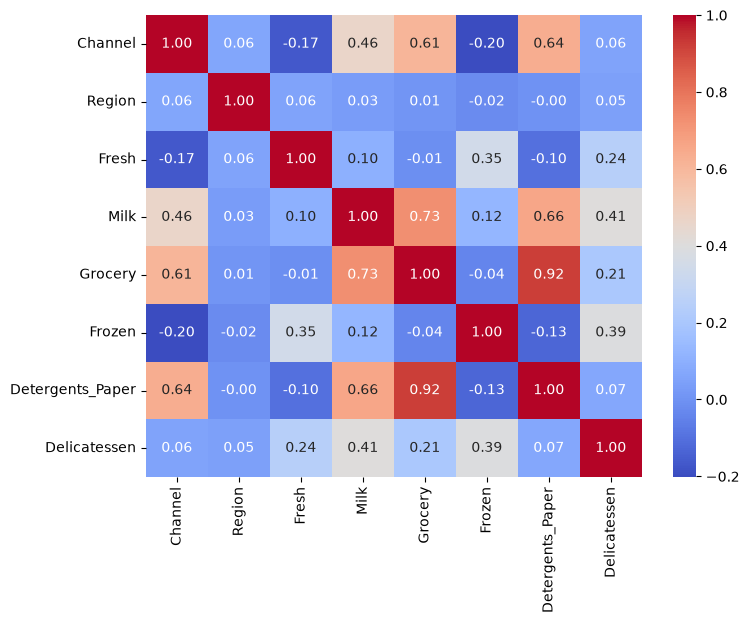

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Region,,,,,,
1,11101.727273,5486.415584,7403.077922,3000.337662,2651.116883,1354.896104
2,9887.680851,5088.170213,9218.595745,4045.361702,3687.468085,1159.702128
3,12533.471519,5977.085443,7896.363924,2944.594937,2817.753165,1620.601266


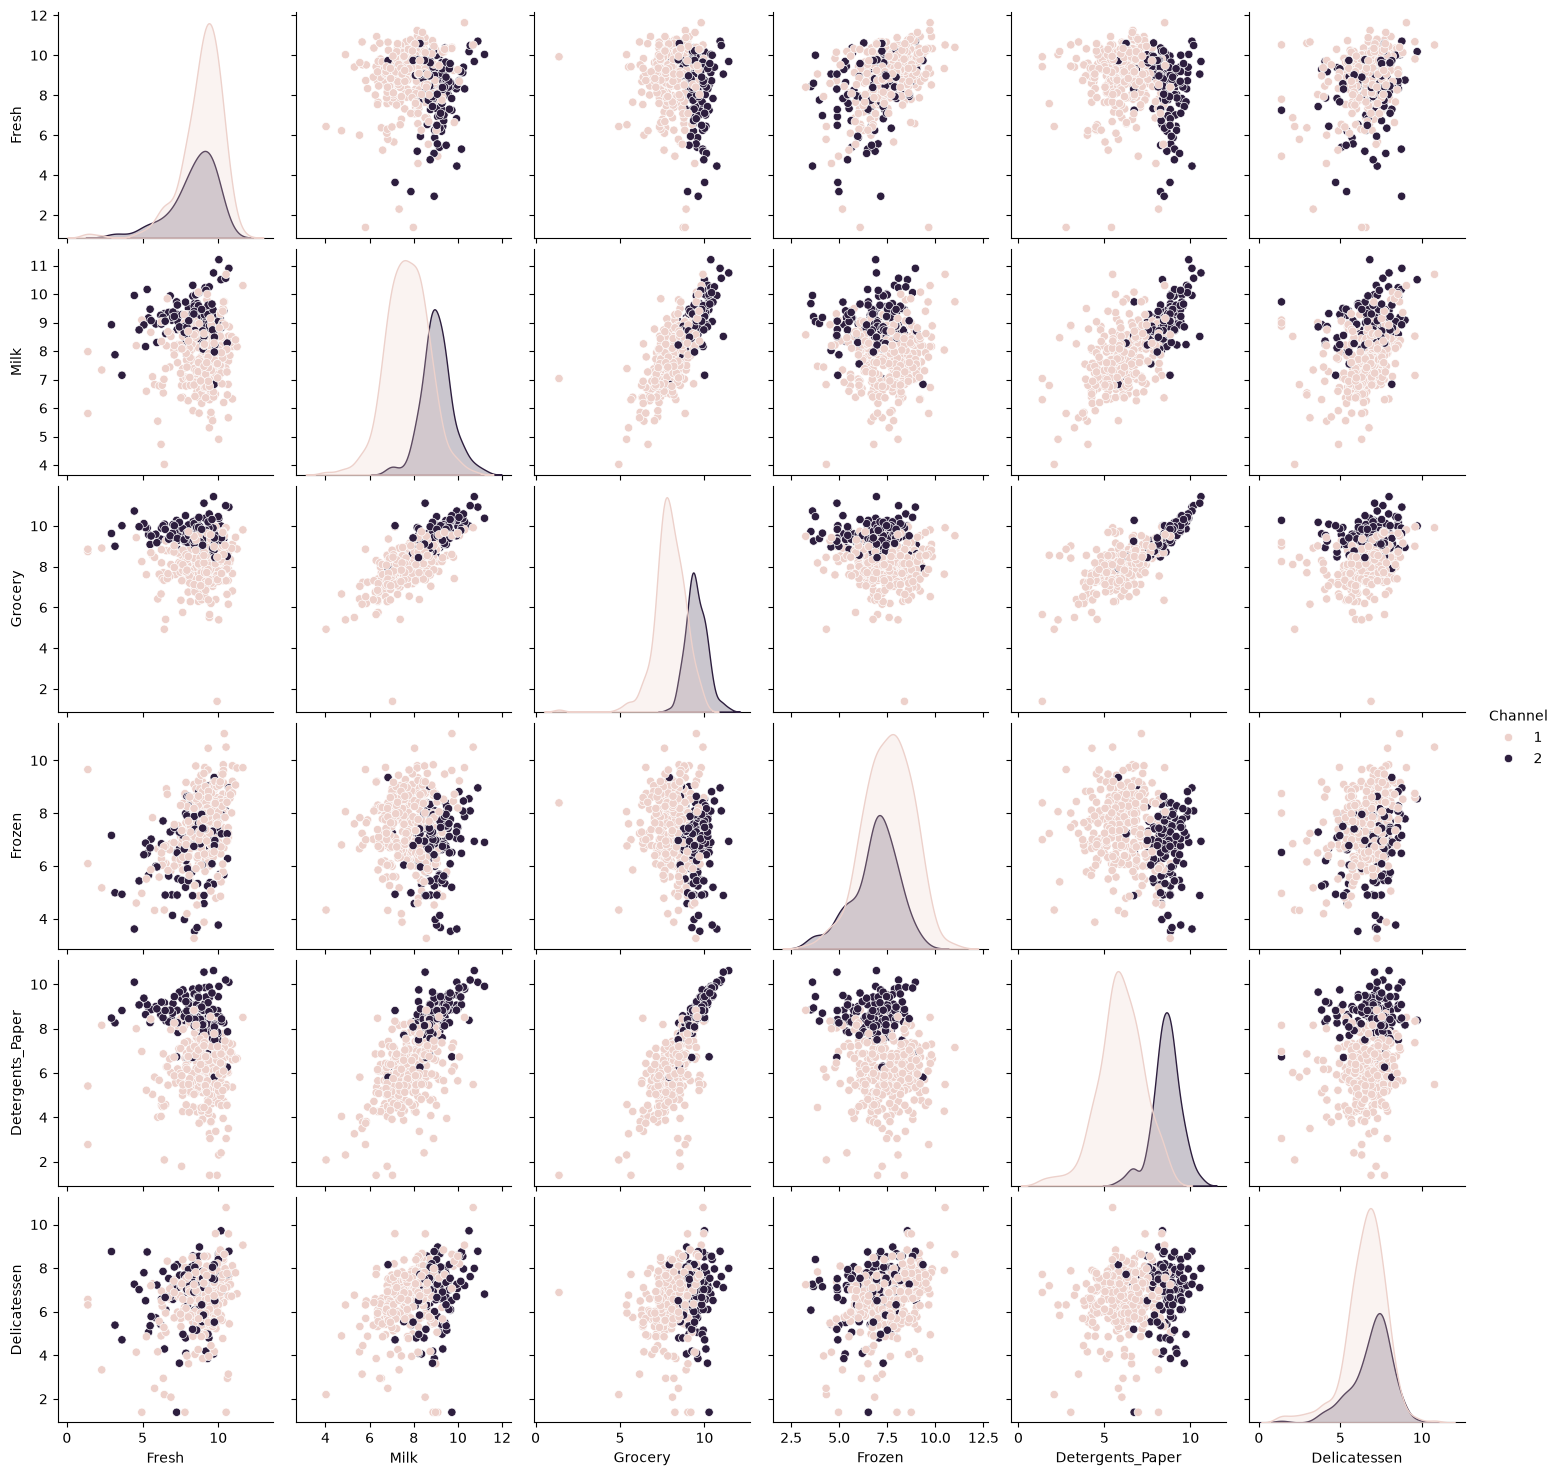

In [15]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f'); plt.show()

sns.pairplot(df_log, hue='Channel', vars=num_cols)

df.groupby('Channel')[num_cols].mean()
df.groupby('Region')[num_cols].mean()

In [16]:
df_log = df.copy()
df_log[num_cols] = np.log1p(df[num_cols])
df_log[num_cols].skew()

Fresh              -1.575326
Milk               -0.224063
Grocery            -0.674938
Frozen             -0.352655
Detergents_Paper   -0.235961
Delicatessen       -1.091827
dtype: float64

In [17]:
from sklearn.preprocessing import StandardScaler

X = df_log[num_cols]
X_scaled = StandardScaler().fit_transform(X)

# optional: one-hot encode Region (a nominal category)
df_model = pd.get_dummies(df_log, columns=['Region'], drop_first=True)